In [1]:
#First, let's open one of the data files
import pickle
with open('../Data/dataset_2011.pkl', 'rb') as infile:
  data_2011 = pickle.load(infile)

In [8]:
#We can look at all the types of information stored in this data

list(data_2011)

['B decay vertex x position',
 'B decay vertex y position',
 'B decay vertex z position',
 'B decay vertex fit chi2',
 'B impact parameter wrt primary vertex',
 'B impact parameter chi2 wrt primary vertex',
 'B flight distance wrt primary vertex',
 'B flight distance chi2 wrt primary vertex',
 'B cos(angle) between line-of-flight and momentum',
 'B magnitude of momentum',
 'B magnitude of momentum transverse to beam',
 'B 4-momentum energy component',
 'B 4-momentum x component',
 'B 4-momentum y component',
 'B 4-momentum z component',
 'B invariant mass',
 'B assumed particle type',
 'B lifetime',
 'Isolation: Charged cone angle',
 'Isolation: Charged cone number of particles contained',
 'Isolation: Charged cone eta difference between cone momentum and B',
 'Isolation: Charged cone phi difference between cone momentum and B',
 'Isolation: Charged cone ratio of B momentum and B+cone momentum all in transverse plane',
 'Isolation: Charged cone 4-momentum of max-PT object energy compon

FitResult of
<ExtendedUnbinnedNLL model=[<zfit.<class 'zfit.models.functor.SumPDF'>  params=[Composed_autoparam_34, Composed_autoparam_35]] data=[<zfit.Data: Data obs=('B invariant mass',) shape=(584370, 1)>] constraints=[]> 
with
<Minuit Minuit, tol=0.001>

╒═════════╤═════════════╤══════════════════╤═════════╤══════════════════════════════╕
│  valid  │  converged  │  param at limit  │   edm   │   approx. fmin (full | opt.) │
╞═════════╪═════════════╪══════════════════╪═════════╪══════════════════════════════╡
│  True   │    True     │      False       │ 8.1e-05 │         3365143.83 | -365942 │
╘═════════╧═════════════╧══════════════════╧═════════╧══════════════════════════════╛

Parameters
name               value  (rounded)        hesse    at limit
---------------  ------------------  -----------  ----------
signalYield                  340383  +/- 6.2e+02       False
backgroundYield              243981  +/- 5.4e+02       False
mean                        5283.38  +/-   0.036       

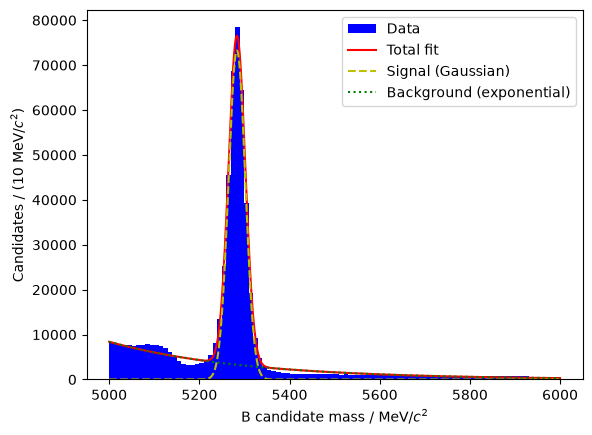

In [23]:
import numpy as np
from matplotlib import pyplot as plt
import zfit

lower, upper = 5000, 6000
mass = zfit.Space('B invariant mass', (lower, upper))

mean  = zfit.Parameter('mean', 5280, 5000, 6000)
sigma = zfit.Parameter('sigma', 20,    5,  100)
signalYield = zfit.Parameter('signalYield', 1e5, 0, 1e6)

signalPDF = zfit.pdf.Gauss(obs=mass, mu=mean, sigma=sigma, extended=signalYield)

exponent  = zfit.Parameter('exponent', -0.01, -1e-1, -1e-6)
backgroundYield = zfit.Parameter('backgroundYield', 4e5, 0, 1e6)

backgroundPDF = zfit.pdf.Exponential(obs=mass, lam=exponent, extended=backgroundYield)

totalPDF = zfit.pdf.SumPDF(pdfs=[signalPDF, backgroundPDF])

zdata = zfit.Data.from_pandas(data_2011, mass)

nll = zfit.loss.ExtendedUnbinnedNLL(model=totalPDF, data=zdata)

minimizer = zfit.minimize.Minuit()
result = minimizer.minimize(nll)


#be checked.
param_hesse = result.hesse()

mu_fit         = result.params[mean]['value']
sigma_fit      = result.params[sigma]['value']
sig_yield_fit  = result.params[signalYield]['value']
back_yield_fit = result.params[backgroundYield]['value']
exponent_fit   = result.params[exponent]['value']


print(result)
print(f"Function minimum: {result.fmin}")
print(f"Converged: {result.converged}")
print(f"Valid: {result.valid}")


n_bins = 100
bin_width = (upper - lower) / n_bins

plt.hist(data_2011['B invariant mass'], bins=n_bins, range=(lower, upper),
          color='blue', label='Data')

x = np.linspace(lower, upper, 1000)
plt.plot(x, np.asarray(totalPDF.ext_pdf(x))      * bin_width, 'r-',  label='Total fit')
plt.plot(x, np.asarray(signalPDF.ext_pdf(x))     * bin_width, 'y--', label='Signal (Gaussian)')
plt.plot(x, np.asarray(backgroundPDF.ext_pdf(x)) * bin_width, 'g:',  label='Background (exponential)')

plt.xlabel(r'B candidate mass / MeV/$c^2$')
plt.ylabel(rf'Candidates / ({bin_width:.0f} MeV/$c^2$)')
plt.legend()
plt.show()

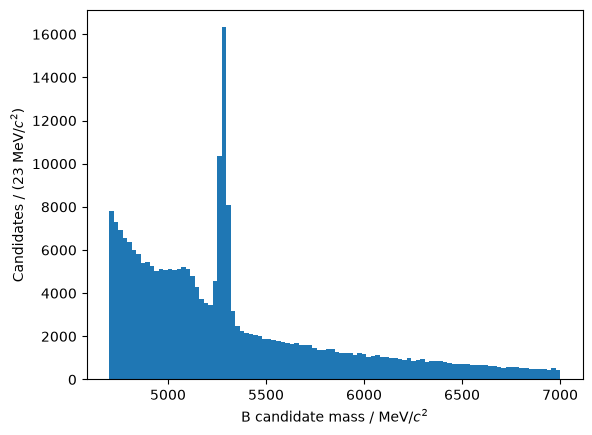

In [11]:
#Most of the real B mesons are actually B -> J/psi K decays. The J/psi is a charm-anticharm meson which decays to our two muons, and
#so, the dimuon system will have a mass consistent with the J/psi meson, 3097 MeV. If we remove these we get

plt.hist(data_2011[abs(data_2011['dimuon-system invariant mass'] - 3097) > 100]['B invariant mass'], bins=100)
plt.xlabel(r'B candidate mass / MeV/$c^2$')
plt.ylabel(r'Candidates / (23 MeV/$c^2)$')
plt.show()

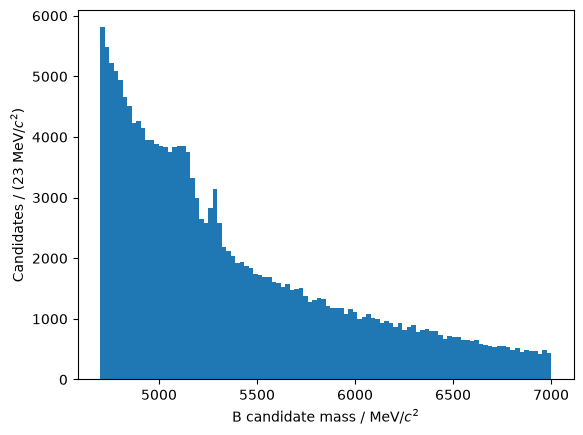

In [12]:
#Now most of what's remaining are actually B -> psi(2S) K decays. The psi(2S) is an excited state of the J/psi.
#It can also decay to our two muons, but now the dimuon system will have a mass consistent with the psi(2S) meson, 3686 MeV.
#If we also remove these, we'll see how much work we've got to do

plt.hist(data_2011[(abs(data_2011['dimuon-system invariant mass'] - 3097) > 100) & (abs(data_2011['dimuon-system invariant mass'] - 3686) > 100)]['B invariant mass'], bins=100)
plt.xlabel(r'B candidate mass / MeV/$c^2$')
plt.ylabel(r'Candidates / (23 MeV/$c^2)$')
plt.show()



## Fetch signal-like data

<>:10: SyntaxWarning: invalid escape sequence '\p'
<>:16: SyntaxWarning: invalid escape sequence '\p'
<>:10: SyntaxWarning: invalid escape sequence '\p'
<>:16: SyntaxWarning: invalid escape sequence '\p'
C:\Users\YaBoiSK\AppData\Local\Temp\ipykernel_24380\3701744383.py:10: SyntaxWarning: invalid escape sequence '\p'
  plt.title('J/$\psi$ Peak')
C:\Users\YaBoiSK\AppData\Local\Temp\ipykernel_24380\3701744383.py:16: SyntaxWarning: invalid escape sequence '\p'
  plt.title('$\psi(2s)$ Peak')


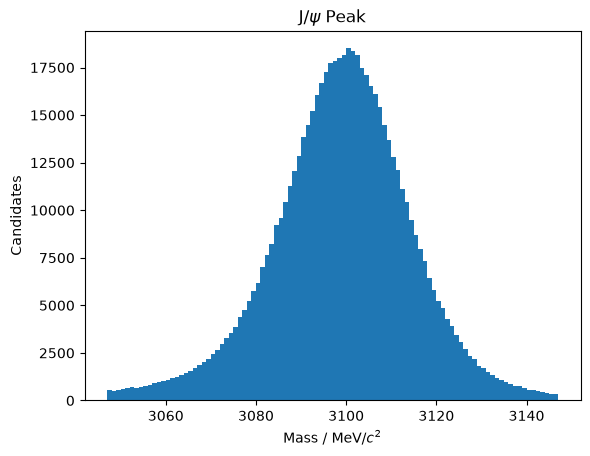

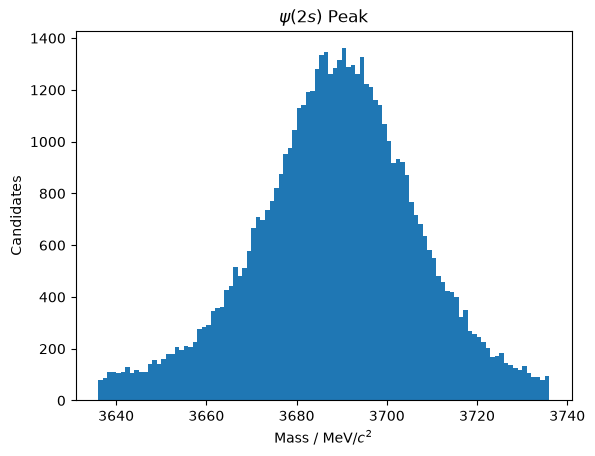

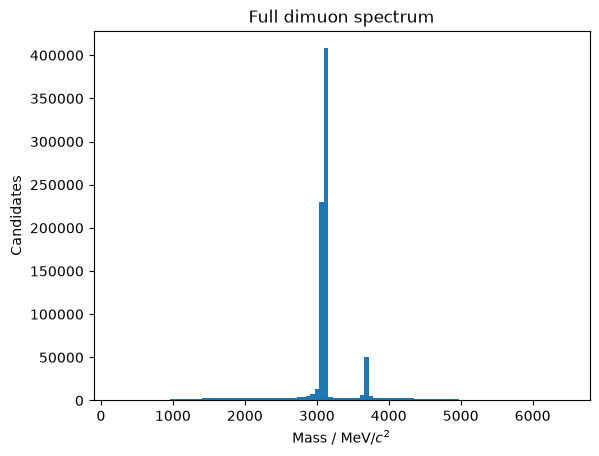

In [29]:
#name this as our data for the future
dimuon_mass = data_2011['dimuon-system invariant mass']
b_mass = data_2011['B invariant mass']

# J/psi and Psi(2s) peaks
j_psi = data_2011[(abs(dimuon_mass - 3097) < 50)]
psi_2s = data_2011[(abs(dimuon_mass - 3686) < 50)]

plt.hist(j_psi['dimuon-system invariant mass'], bins=100)
plt.title('J/$\psi$ Peak')
plt.xlabel(r'Mass / MeV/$c^2$')
plt.ylabel(r'Candidates')
plt.show()

plt.hist(psi_2s['dimuon-system invariant mass'], bins=100)
plt.title('$\psi(2s)$ Peak')
plt.xlabel(r'Mass / MeV/$c^2$')
plt.ylabel(r'Candidates')
plt.show()

plt.hist(dimuon_mass, bins=100)
plt.title('Full dimuon spectrum')
plt.xlabel(r'Mass / MeV/$c^2$')
plt.ylabel(r'Candidates')
plt.show()

## Fetch noise-like data

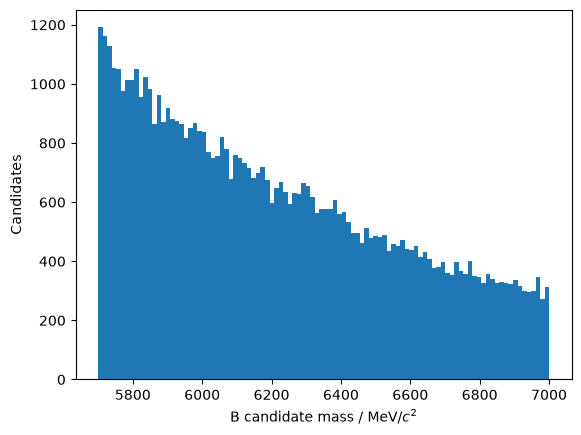

In [14]:
noise_like = data_2011[b_mass > 5700]

plt.hist(noise_like['B invariant mass'], bins=100)
plt.xlabel(r'B candidate mass / MeV/$c^2$')
plt.ylabel(r'Candidates')
plt.show()

## Identify how features vary between datasets

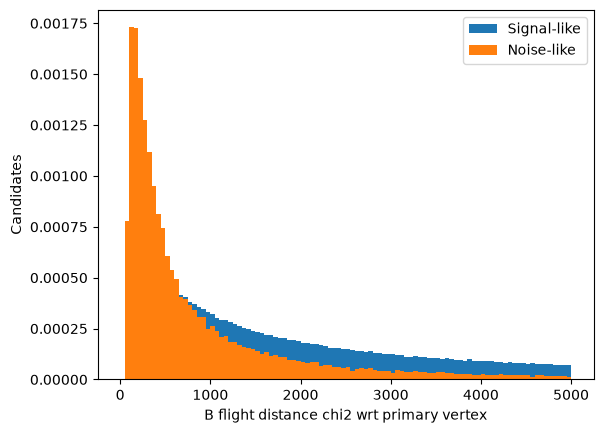

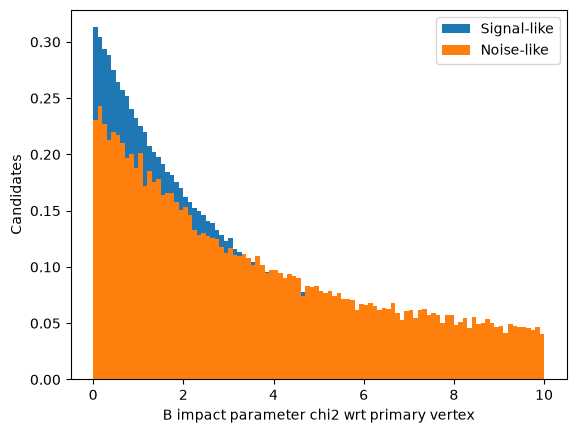

In [15]:
plt.hist(signal_like['B flight distance chi2 wrt primary vertex'], bins=100, range=(0, 5000), label='Signal-like', density=True)
plt.hist(noise_like['B flight distance chi2 wrt primary vertex'], bins=100, range=(0, 5000), label='Noise-like', density=True)
plt.xlabel(r'B flight distance chi2 wrt primary vertex')
plt.ylabel(r'Candidates')
plt.legend()
plt.show()

plt.hist(signal_like['B impact parameter chi2 wrt primary vertex'], bins=100, range=(0, 10), label='Signal-like', density=True)
plt.hist(noise_like['B impact parameter chi2 wrt primary vertex'], bins=100, range=(0, 10), label='Noise-like', density=True)
plt.xlabel(r'B impact parameter chi2 wrt primary vertex')
plt.ylabel(r'Candidates')
plt.legend()
plt.show()

#This doesn't look great, they are on top of each other. There appears to be no
#separating power, but let's look in 2D



## XGBoost Part

In [16]:
import xgboost
import pandas

model = xgboost.XGBClassifier(eval_metric='auc', early_stopping_rounds=50, n_estimators=1000, learning_rate=0.3, max_depth=6)

nSignalTotal = len(signal_like)
nBackgroundTotal = len(noise_like)

#vary thesse
chosen_variables = [
'B decay vertex x position',
'B decay vertex y position',
'B decay vertex z position',
'B decay vertex fit chi2',
'B impact parameter wrt primary vertex',
'B impact parameter chi2 wrt primary vertex',
'B flight distance wrt primary vertex',
'B flight distance chi2 wrt primary vertex',
'B cos(angle) between line-of-flight and momentum',
'B magnitude of momentum'
]

#train/test split
nSignalTrain = int(0.9*nSignalTotal)
nSignalTest  = nSignalTotal - nSignalTrain
nBackgroundTrain = int(0.9*nBackgroundTotal)
nBackgroundTest  = nBackgroundTotal - nBackgroundTrain

#train
x_train = pandas.concat([signal_like[chosen_variables][:nSignalTrain], noise_like[chosen_variables][:nBackgroundTrain]], axis=0, ignore_index=True)
y_train = [1]*nSignalTrain + [0]*nBackgroundTrain

#test
x_test = pandas.concat([signal_like[chosen_variables][nSignalTrain:], noise_like[chosen_variables][nBackgroundTrain:]], axis=0, ignore_index=True)
y_test  = [1]*nSignalTest + [0]*nBackgroundTest

model.fit(x_train, y_train, eval_set=[(x_test,y_test)])


[0]	validation_0-auc:0.89977
[1]	validation_0-auc:0.91605
[2]	validation_0-auc:0.92213
[3]	validation_0-auc:0.92627
[4]	validation_0-auc:0.93000
[5]	validation_0-auc:0.93246
[6]	validation_0-auc:0.93445
[7]	validation_0-auc:0.93809
[8]	validation_0-auc:0.93991
[9]	validation_0-auc:0.94150
[10]	validation_0-auc:0.94262
[11]	validation_0-auc:0.94420
[12]	validation_0-auc:0.94489
[13]	validation_0-auc:0.94618
[14]	validation_0-auc:0.94713
[15]	validation_0-auc:0.94790
[16]	validation_0-auc:0.94847
[17]	validation_0-auc:0.94885
[18]	validation_0-auc:0.94984
[19]	validation_0-auc:0.95009
[20]	validation_0-auc:0.95052
[21]	validation_0-auc:0.95100
[22]	validation_0-auc:0.95114
[23]	validation_0-auc:0.95161
[24]	validation_0-auc:0.95182
[25]	validation_0-auc:0.95236
[26]	validation_0-auc:0.95253
[27]	validation_0-auc:0.95273
[28]	validation_0-auc:0.95279
[29]	validation_0-auc:0.95313
[30]	validation_0-auc:0.95336
[31]	validation_0-auc:0.95345
[32]	validation_0-auc:0.95364
[33]	validation_0-au

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",50
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'auc'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


## XGBoost Results

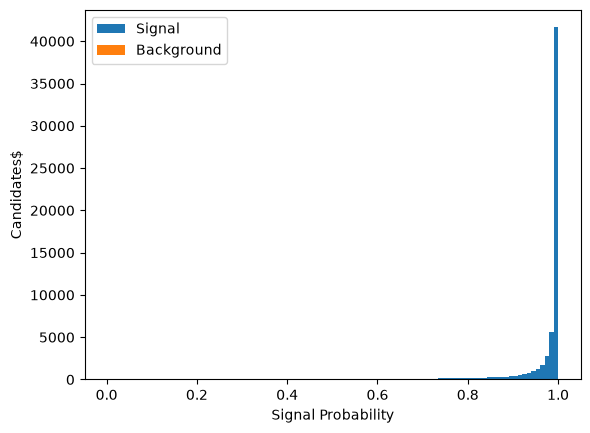

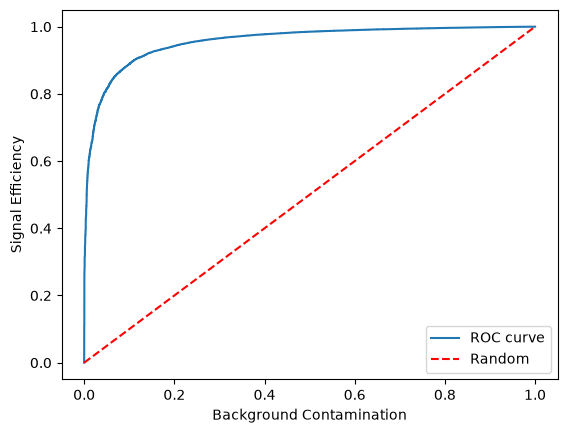

In [17]:
from sklearn.metrics import roc_curve

prediction = model.predict_proba(x_test)

plt.hist([p[1] for p,cls in zip(prediction, y_test) if cls == 1], bins=100, label='Signal')
plt.hist([p[1] for p,cls in zip(prediction, y_test) if cls == 0], bins=100, label='Background')
plt.xlabel(r'Signal Probability')
plt.ylabel(r'Candidates$')
plt.legend()
plt.show()

background_accepted, signal_accepted, probabilities_tested = roc_curve(y_test, prediction[:,1])
plt.plot(background_accepted, signal_accepted, label='ROC curve')
plt.plot([0,1], [0,1], color='red', linestyle='--', label = 'Random')
plt.xlabel(r'Background Contamination')
plt.ylabel(r'Signal Efficiency')
plt.legend()
plt.show()

In [47]:
list(data_2011)

['B decay vertex x position',
 'B decay vertex y position',
 'B decay vertex z position',
 'B decay vertex fit chi2',
 'B impact parameter wrt primary vertex',
 'B impact parameter chi2 wrt primary vertex',
 'B flight distance wrt primary vertex',
 'B flight distance chi2 wrt primary vertex',
 'B cos(angle) between line-of-flight and momentum',
 'B magnitude of momentum',
 'B magnitude of momentum transverse to beam',
 'B 4-momentum energy component',
 'B 4-momentum x component',
 'B 4-momentum y component',
 'B 4-momentum z component',
 'B invariant mass',
 'B assumed particle type',
 'B lifetime',
 'Isolation: Charged cone angle',
 'Isolation: Charged cone number of particles contained',
 'Isolation: Charged cone eta difference between cone momentum and B',
 'Isolation: Charged cone phi difference between cone momentum and B',
 'Isolation: Charged cone ratio of B momentum and B+cone momentum all in transverse plane',
 'Isolation: Charged cone 4-momentum of max-PT object energy compon

**Task 5: K+ mu- two body system**

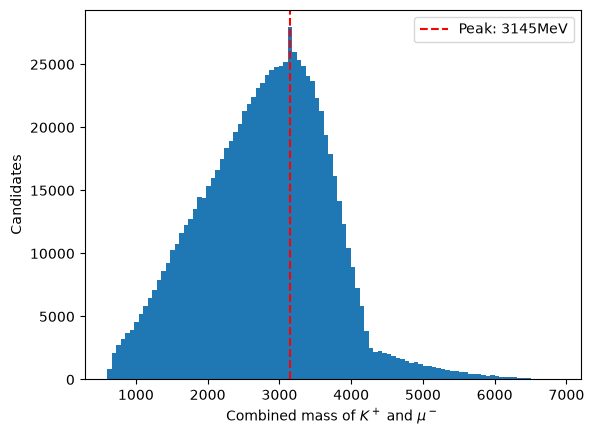

In [74]:
import numpy as np

k_inv_mass = data_2011['Kaon invariant mass']
mu_inv_mass = data_2011['Opposite-sign muon invariant mass']

k_energy = data_2011['Kaon 4-momentum energy component']
k_px = data_2011['Kaon 4-momentum x component']
k_py = data_2011['Kaon 4-momentum y component']
k_pz = data_2011['Kaon 4-momentum z component']

mu_energy = data_2011['Opposite-sign muon 4-momentum energy component']
mu_px = data_2011['Opposite-sign muon 4-momentum x component']
mu_py = data_2011['Opposite-sign muon 4-momentum y component']
mu_pz = data_2011['Opposite-sign muon 4-momentum z component']


combined_energy = k_energy + mu_energy
combined_px = k_px + mu_px
combined_py = k_py + mu_py
combined_pz = k_pz + mu_pz
combined_p = np.sqrt(combined_px**2 + combined_py**2 + combined_pz**2)

mass = np.sqrt(combined_energy**2 - combined_p**2)

counts, edges, _ = plt.hist(mass, bins=100)
i = np.argmax(counts)
peak = 0.5 * (edges[i] + edges[i + 1])   # centre of the tallest bin

plt.xlabel(r'Combined mass of $K^+$ and $\mu^-$')
plt.ylabel('Candidates')
plt.axvline(peak, linestyle='--', color='red', label=f'Peak: {peak:.0f}MeV')
plt.legend()
plt.show()


In [66]:
mass.mode()[0]


np.float64(5947.52341107142)